# 8. 2D Silicon Nanowire Array for Photovoltaics: Efficiency and Dispersion

## Physical Motivation & Learning Objectives
Silicon nanowire arrays enhance solar cell light trapping through localized optical resonances and subwavelength scattering. In this tutorial:
1. We simulate a 2D square array of vertical silicon nanowires.
2. We compute photovoltaic figures of merit: short-circuit current density $J_{\mathrm{sc}}$ and ultimate efficiency $\eta$ under AM1.5G solar illumination.
3. We plot the modal dispersion diagram (`plotting.omega_plot`).

> [!NOTE]
> **Meshing Workflow: Classic Gmsh / Pre-Generated Mesh (`examples/`)**
> This notebook uses EMUstack's classic meshing workflow (`make_mesh_now=True, lc_bkg=0.1, lc2=2.0` or loading pre-generated `.mail` meshes from `EMUstack/backend/data/meshes/`).


**Legacy example.** This notebook reproduces `simo_040-2D_array.py` from the original EMUstack. The `LEGACY_PARAMS` switch in the next cell selects the inputs:

- `LEGACY_PARAMS = True` *(default)*: the legacy inputs, unchanged. About 5 minutes. T, R and A then agree with legacy EMUstack to 1e-7, on the same mesh (checked in `benchmarks/parity/`, `examples/` version, see `PARITY_RESULTS.md`).
- `LEGACY_PARAMS = False`: 12 wavelengths instead of 3 and 50 Bloch modes instead of 200.

In [ ]:
# True: the inputs of the original EMUstack example, unchanged.
# False: same structure, 12 wavelengths instead of 3, 50 Bloch modes instead of 200.
LEGACY_PARAMS = True


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



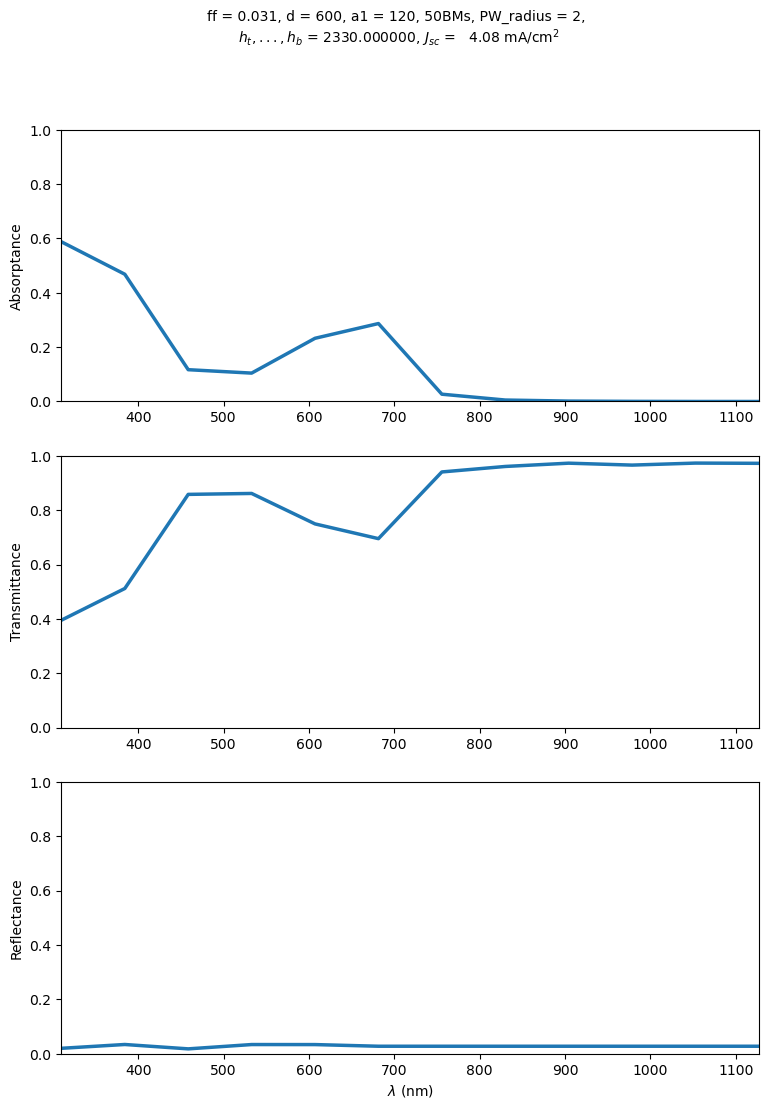

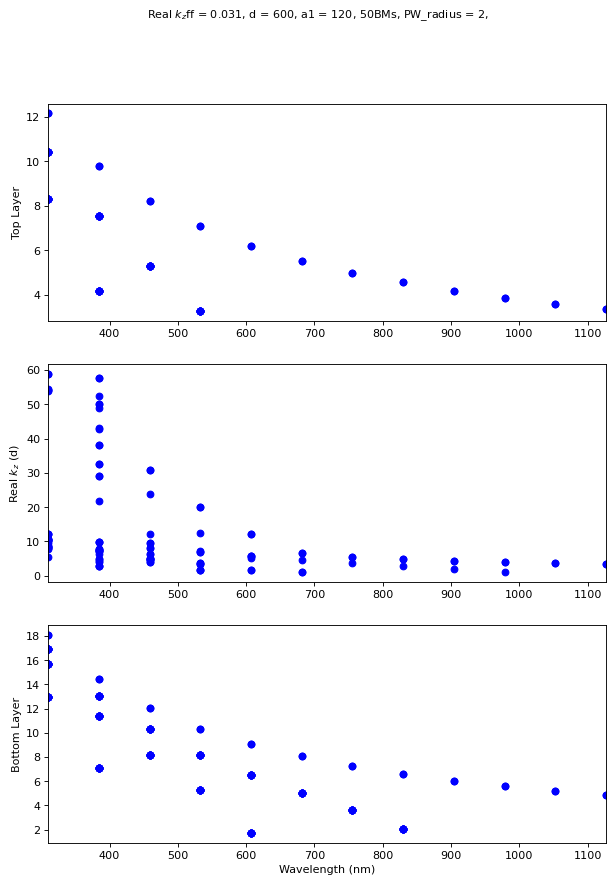

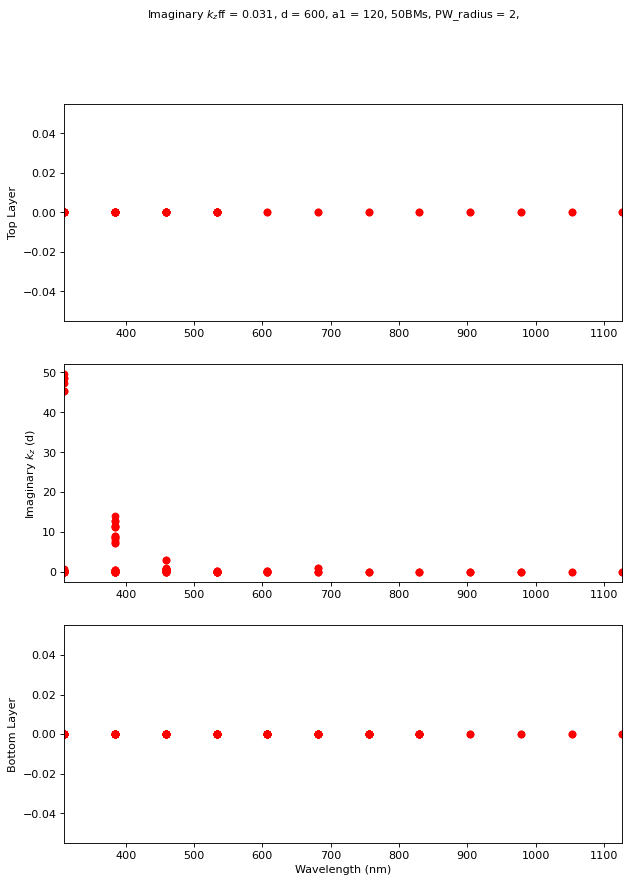

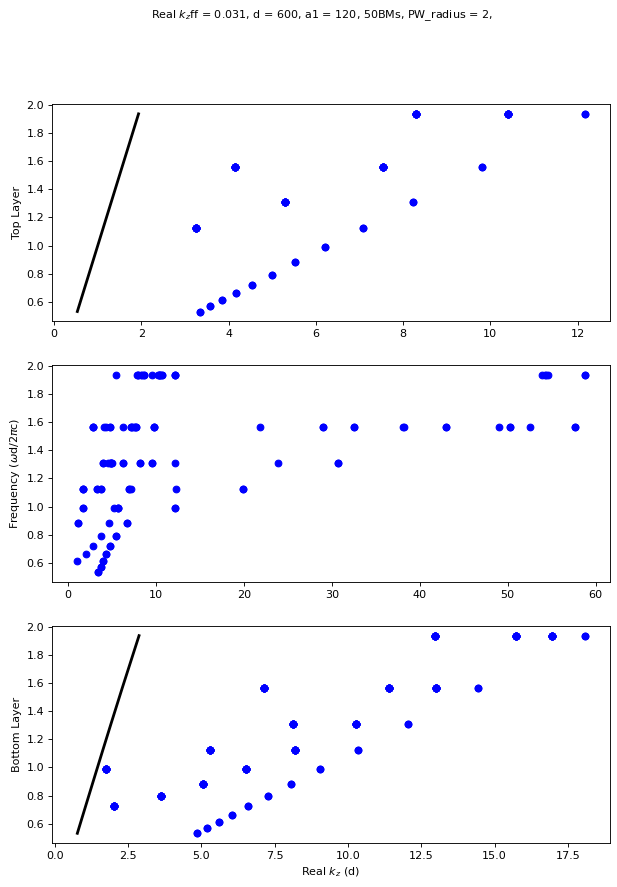

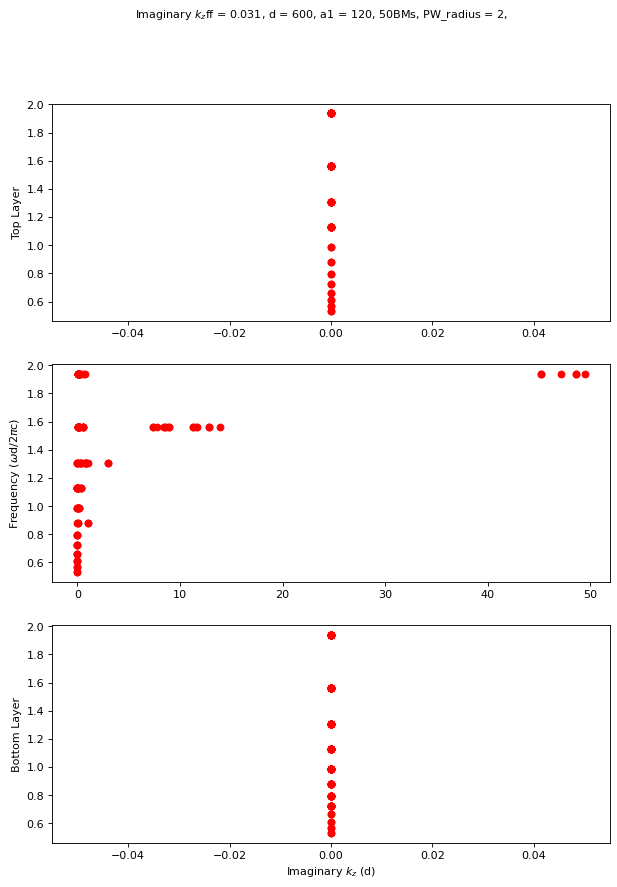

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl_1 = 310.0
wl_2 = 1127.0
no_wl_1 = 3 if LEGACY_PARAMS else 12
wavelengths = np.linspace(wl_1, wl_2, no_wl_1)
light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

period = 600.0
num_BMs = 200 if LEGACY_PARAMS else 50

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.SiO2, loss=False)

NW_diameter = 120.0
NW_array = objects.NanoStruct(
    '2D_array', period, NW_diameter, height_nm=2330.0,
    inclusion_a=materials.Si_c, background=materials.Air, loss=True,
    make_mesh_now=True, force_mesh=True, lc_bkg=0.1, lc2=2.0
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_nws = NW_array.calc_modes(light, num_BMs=num_BMs)
    stk = Stack((sim_sub, sim_nws, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor(max_workers=24) as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))

figs_tra = plotting.t_r_a_plots(stacks_list, active_layer_nu=1, J_sc=True)
plt.show()

fig_om = plotting.omega_plot(stacks_list, wavelengths)
plt.show()


## Nanowire Array Parameters


## Photovoltaic Figures of Merit: $J_{\mathrm{sc}}$ and Ultimate Efficiency $\eta$


## Physical Interpretation
- Nanowire arrays demonstrate broadband absorption enhancement over flat silicon slabs due to excitation of guided Bloch modes.
- The dispersion diagram illustrates band crossings and anti-crossings corresponding to leaky optical resonances.
